# 03 · Time-Series Modelling: ARMA / ARIMA / SARIMA

**Goal:** forecast **monthly mean discharge** at Kodumudi with classical time-series models, selected and evaluated *without peeking at the test data*.

**Method**
1. Decompose the series (trend / seasonality / residual) to see what a model has to capture.
2. Test stationarity (ADF + KPSS) and read ACF/PACF to choose candidate orders.
3. Fit a **grid of ARIMA and seasonal ARIMA (SARIMA)** models on the training period and rank them by AIC.
4. Compare the finalists on a **validation** period using *one-step-ahead* forecasts, pick one.
5. Check **residual diagnostics** (Ljung-Box, normality, heteroskedasticity).
6. Refit on train + validation and score **once** on the test months (May 2012 – Dec 2015) — the same months used by the ML notebook.

> ⚠️ Requires `statsmodels`. The SARIMA grid fits ~70 models and takes a few minutes.
>
> **One-step-ahead vs. multi-step:** in one-step-ahead evaluation, each month is forecast from all *earlier* observed months (the model parameters stay fixed). A multi-step forecast of the whole 44-month test period from a single origin quickly converges to the long-run mean and looks much worse. We report both, so the two ways of scoring are not confused.

In [1]:
import sys, warnings, time
sys.path.append("../src")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox

import kodumudi as kd

plt.style.use("seaborn-v0_8-whitegrid")
FIG_DIR, TAB_DIR = "../reports/figures", "../reports/tables"
def save_fig(name): plt.savefig(f"{FIG_DIR}/{name}.png", dpi=150, bbox_inches="tight")

daily   = kd.load_daily()
monthly = kd.aggregate(daily, "MS")
annual  = kd.aggregate(daily, "YS")
ts = monthly["discharge_m3s"].asfreq("MS")

train_s = ts[ts.index <  kd.VAL_START]
val_s   = ts[(ts.index >= kd.VAL_START) & (ts.index < kd.TEST_START)]
test_s  = ts[ts.index >= kd.TEST_START]
print(f"Train {len(train_s)} | Validation {len(val_s)} | Test {len(test_s)} months")

Train 345 | Validation 43 | Test 44 months


## 1 · Decomposition: what does the model need to capture?
STL splits the series into trend + seasonal + remainder. **Strength of seasonality** (Hyndman): `F_s = max(0, 1 − Var(remainder) / Var(seasonal + remainder))` — close to 1 means a strongly seasonal series.

Strength of seasonality F_s = 0.64 | strength of trend F_t = 0.24


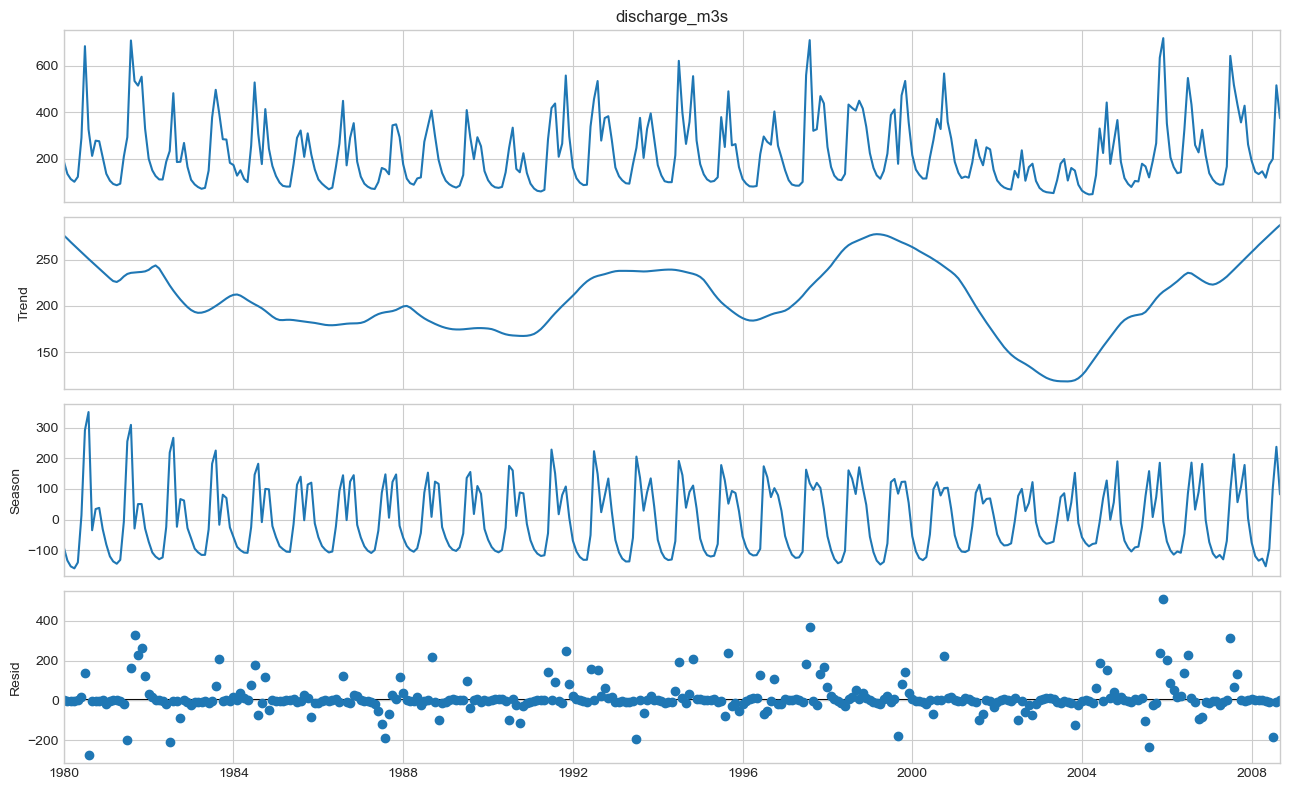

In [2]:
stl = STL(train_s, period=12, robust=True).fit()
Fs = max(0, 1 - np.var(stl.resid) / np.var(stl.seasonal + stl.resid))
Ft = max(0, 1 - np.var(stl.resid) / np.var(stl.trend + stl.resid))
print(f"Strength of seasonality F_s = {Fs:.2f} | strength of trend F_t = {Ft:.2f}")
fig = stl.plot(); fig.set_size_inches(13, 8); plt.tight_layout(); save_fig("03_stl"); plt.show()

## 2 · Stationarity
* **ADF test**: H₀ = unit root (non-stationary). Small p (< 0.05) → evidence *for* stationarity.
* **KPSS test**: H₀ = stationary (the null is flipped!). Large p (> 0.05) → evidence *for* stationarity.
* If they disagree, the series is probably trend- or difference-stationary.

A strongly seasonal series has a *periodic* (non-constant) mean, so we test three versions: the raw series, **anomalies** (monthly climatology removed), and the **seasonally differenced** series (`x_t − x_{t−12}`). The original project tested only the *annual* series, so that is included for comparison.

In [3]:
def stationarity(series, name):
    a = adfuller(series, autolag="AIC")
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")      # p-value is clipped to the 0.01-0.10 table range; expected
        k = kpss(series, regression="c", nlags="auto")
    adf_ok, kpss_ok = a[1] < 0.05, k[1] > 0.05
    verdict = ("stationary" if adf_ok and kpss_ok else
               "non-stationary" if (not adf_ok and not kpss_ok) else "tests disagree")
    return {"series": name, "n": len(series), "ADF stat": a[0], "ADF p": a[1],
            "KPSS stat": k[0], "KPSS p (clipped to 0.01–0.10)": k[1], "verdict": verdict}

clim = train_s.groupby(train_s.index.month).mean()
anom = train_s - train_s.index.month.map(clim).values
tests = pd.DataFrame([
    stationarity(train_s, "Monthly raw (train)"),
    stationarity(anom, "Monthly anomalies (train)"),
    stationarity(train_s.diff(12).dropna(), "Monthly seasonal difference (train)"),
    stationarity(annual["discharge_m3s"], "Annual mean (full 36 yrs)"),
]).set_index("series")
tests.round(4)

,n,ADF stat,ADF p,KPSS stat,KPSS p (clipped to 0.01–0.10),verdict
series,,,,,,
Monthly raw (train),345,-2.6603,0.0812,0.0954,0.1,tests disagree
Monthly anomalies (train),345,-10.4265,0.0000,0.1235,0.1,stationary
Monthly seasonal difference (train),333,-5.3804,0.0000,0.0408,0.1,stationary
Annual mean (full 36 yrs),36,-3.5739,0.0063,0.1121,0.1,stationary


## 3 · ACF / PACF
* **ACF** decaying slowly → persistence; spikes at lag 12, 24, 36 → **seasonality**.
* **PACF** cutting off after lag *p* suggests an AR(*p*) term; ACF cutting off after lag *q* suggests MA(*q*).
Comparing the raw series with the anomalies shows how much of the autocorrelation is just the seasonal cycle.

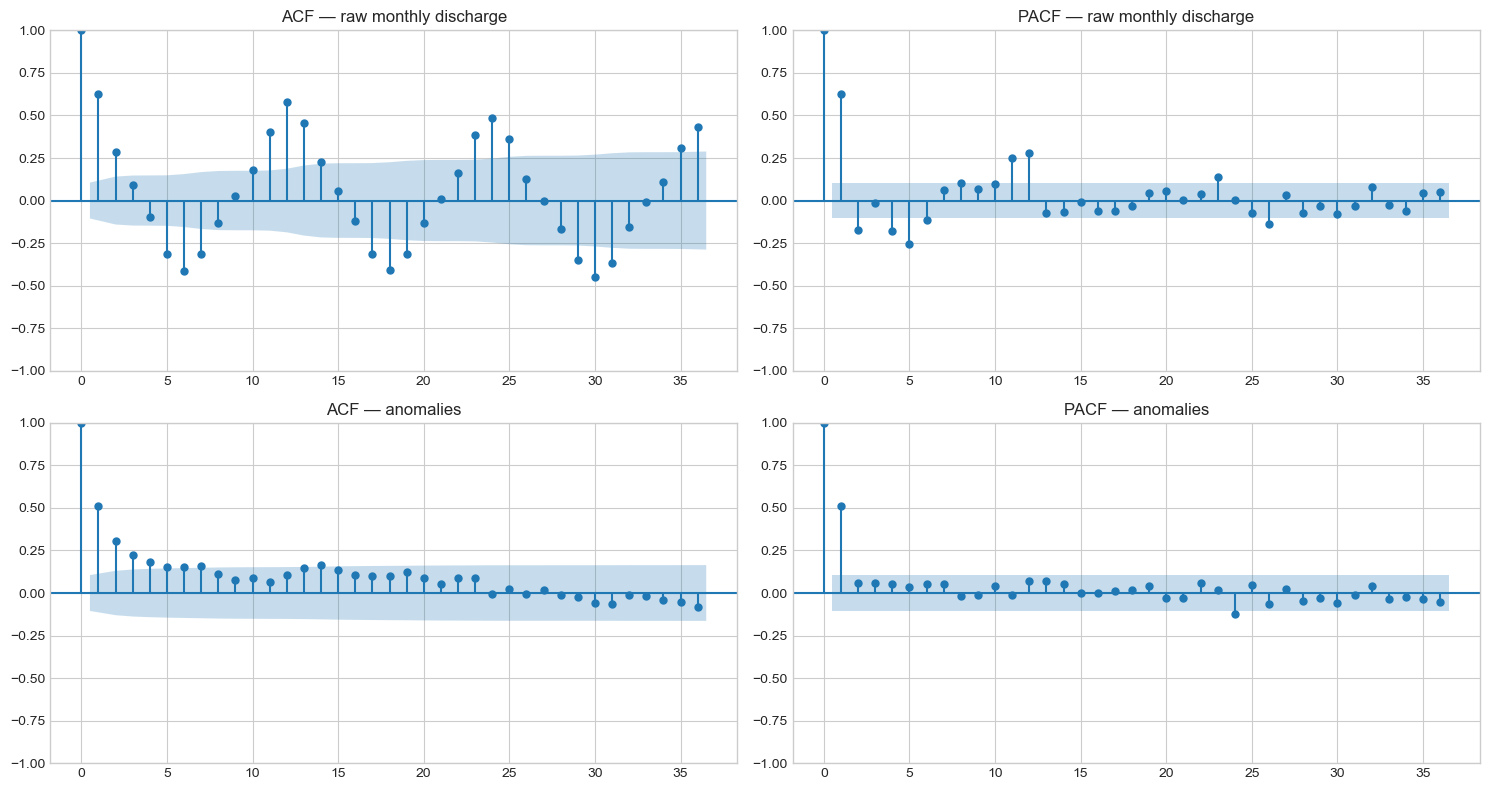

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(15, 8))
plot_acf(train_s, lags=36, ax=axes[0, 0], title="ACF — raw monthly discharge")
plot_pacf(train_s, lags=36, ax=axes[0, 1], method="ywm", title="PACF — raw monthly discharge")
plot_acf(anom, lags=36, ax=axes[1, 0], title="ACF — anomalies")
plot_pacf(anom, lags=36, ax=axes[1, 1], method="ywm", title="PACF — anomalies")
plt.tight_layout(); save_fig("03_acf_pacf"); plt.show()

## 4 · Candidate models — grid search on the training period
`ARIMA(p, 0, q) × (P, D, Q, 12)` with `p, q ∈ {0, 1, 2}`, `P, Q ∈ {0, 1}`, `D ∈ {0, 1}`.

* statsmodels includes a constant automatically when there is no differencing (`d = D = 0`), and omits it otherwise.
* **AIC is only comparable between models with the same differencing**, so AIC ranks are formed separately for `D = 0` and `D = 1`. Models are then compared across `D` on the **validation** set, where all are scored on the same data.

In [5]:
seasonal_options = [(0, 0), (1, 0), (0, 1), (1, 1)]
rows, t0 = [], time.time()
for D in (0, 1):
    for P, Q in seasonal_options:
        for p in range(3):
            for q in range(3):
                so = (P, D, Q, 12) if (P, D, Q) != (0, 0, 0) else (0, 0, 0, 0)
                try:
                    with warnings.catch_warnings():
                        warnings.simplefilter("ignore")
                        r = ARIMA(train_s, order=(p, 0, q), seasonal_order=so).fit()
                    ok = bool(getattr(r, "mle_retvals", {}).get("converged", True))
                    rows.append({"order": (p, 0, q), "seasonal_order": so, "D": D,
                                 "AIC": r.aic, "BIC": r.bic, "converged": ok})
                except Exception as e:
                    rows.append({"order": (p, 0, q), "seasonal_order": so, "D": D,
                                 "AIC": np.nan, "BIC": np.nan, "converged": False})
print(f"Fitted {len(rows)} candidates in {time.time() - t0:.0f}s")
grid = pd.DataFrame(rows)
print(f"{(~grid['converged']).sum()} candidate(s) did not converge and are excluded from the ranking")
grid = grid[grid["converged"]].dropna()
for D in (0, 1):
    print(f"\nTop 5 by AIC with D={D}:")
    print(grid[grid["D"] == D].sort_values("AIC").head(5).drop(columns="converged").round(1).to_string(index=False))

Fitted 72 candidates in 77s
3 candidate(s) did not converge and are excluded from the ranking

Top 5 by AIC with D=0:
    order seasonal_order  D    AIC    BIC
(1, 0, 0)  (1, 0, 1, 12)  0 4075.5 4094.7
(1, 0, 1)  (1, 0, 1, 12)  0 4076.5 4099.6
(2, 0, 0)  (1, 0, 1, 12)  0 4076.7 4099.8
(1, 0, 2)  (1, 0, 1, 12)  0 4077.7 4104.6
(2, 0, 1)  (1, 0, 1, 12)  0 4078.5 4105.4

Top 5 by AIC with D=1:
    order seasonal_order  D    AIC    BIC
(2, 0, 1)  (0, 1, 1, 12)  1 3930.2 3949.3
(2, 0, 1)  (1, 1, 1, 12)  1 3931.9 3954.8
(2, 0, 2)  (0, 1, 1, 12)  1 3932.2 3955.1
(1, 0, 0)  (0, 1, 1, 12)  1 3932.9 3944.3
(1, 0, 2)  (0, 1, 1, 12)  1 3933.1 3952.2


## 5 · Choose among finalists on the validation set (one-step-ahead)
Finalists = the 2 best-AIC models for each `D`, plus the **non-seasonal ARMA(1,1)** used in the original course notebook as a reference point.

In [6]:
def one_step(res_fitted, new_obs):
    """One-step-ahead forecasts for `new_obs`: parameters fixed, state updated with each new observation."""
    r = res_fitted.append(new_obs, refit=False)
    return r.get_prediction(start=new_obs.index[0], end=new_obs.index[-1]).predicted_mean

finalists = []
for D in (0, 1):
    top = grid[grid["D"] == D].sort_values("AIC").head(2)
    finalists += [(r.order, r.seasonal_order) for r in top.itertuples()]
finalists.append(((1, 0, 1), (0, 0, 0, 0)))          # original reference model
finalists = list(dict.fromkeys(finalists))

def label(order, so):
    return f"ARIMA{order}" if so == (0, 0, 0, 0) else f"SARIMA{order}x{so[:3]}[12]"

val_rows = {}
for order, so in finalists:
    r = ARIMA(train_s, order=order, seasonal_order=so).fit()
    val_rows[label(order, so)] = kd.evaluate(val_s, one_step(r, val_s))
val_table = pd.DataFrame(val_rows).T.sort_values("RMSE")
best_label = val_table.index[0]
best_order, best_so = next((o, s) for o, s in finalists if label(o, s) == best_label)
print(f"Selected on validation RMSE: {best_label}")
val_table.round(3)

Selected on validation RMSE: SARIMA(1, 0, 1)x(1, 0, 1)[12]


,MAE,MSE,RMSE,NSE
"SARIMA(1, 0, 1)x(1, 0, 1)[12]",59.348,9845.602,99.225,0.592
"SARIMA(2, 0, 1)x(0, 1, 1)[12]",61.263,9892.894,99.463,0.590
"SARIMA(1, 0, 0)x(1, 0, 1)[12]",59.779,10031.295,100.156,0.584
"SARIMA(2, 0, 1)x(1, 1, 1)[12]",61.476,10122.488,100.611,0.580
"ARIMA(1, 0, 1)",83.716,15109.091,122.919,0.373


## 6 · Residual diagnostics for the selected model
A good model leaves **white-noise** residuals:
* **Ljung-Box** (H₀ = no autocorrelation): p > 0.05 is what we want. `model_df` corrects the degrees of freedom for the number of fitted ARMA parameters.
* **Jarque-Bera** (H₀ = normal residuals) — monthly river flow is skewed, so some non-normality is expected.
* **Breakvar** (H₀ = constant variance) — flood months usually have larger errors, so heteroskedasticity is common.

Ljung-Box (want p > 0.05):
    lb_stat  lb_pvalue
12   6.0409     0.6427
24  17.0140     0.6521

Jarque-Bera p = 0.0000 | skew = 1.57 | kurtosis = 8.02
Heteroskedasticity (breakvar) p = 0.3284
AR roots modulus: [1.    1.    1.    1.    1.    1.    1.    1.    1.    1.    1.    1.
 1.665] | MA roots modulus: [1.001 1.001 1.001 1.001 1.001 1.001 1.001 1.001 1.001 1.001 1.001 1.001
 9.392] (all should be > 1)


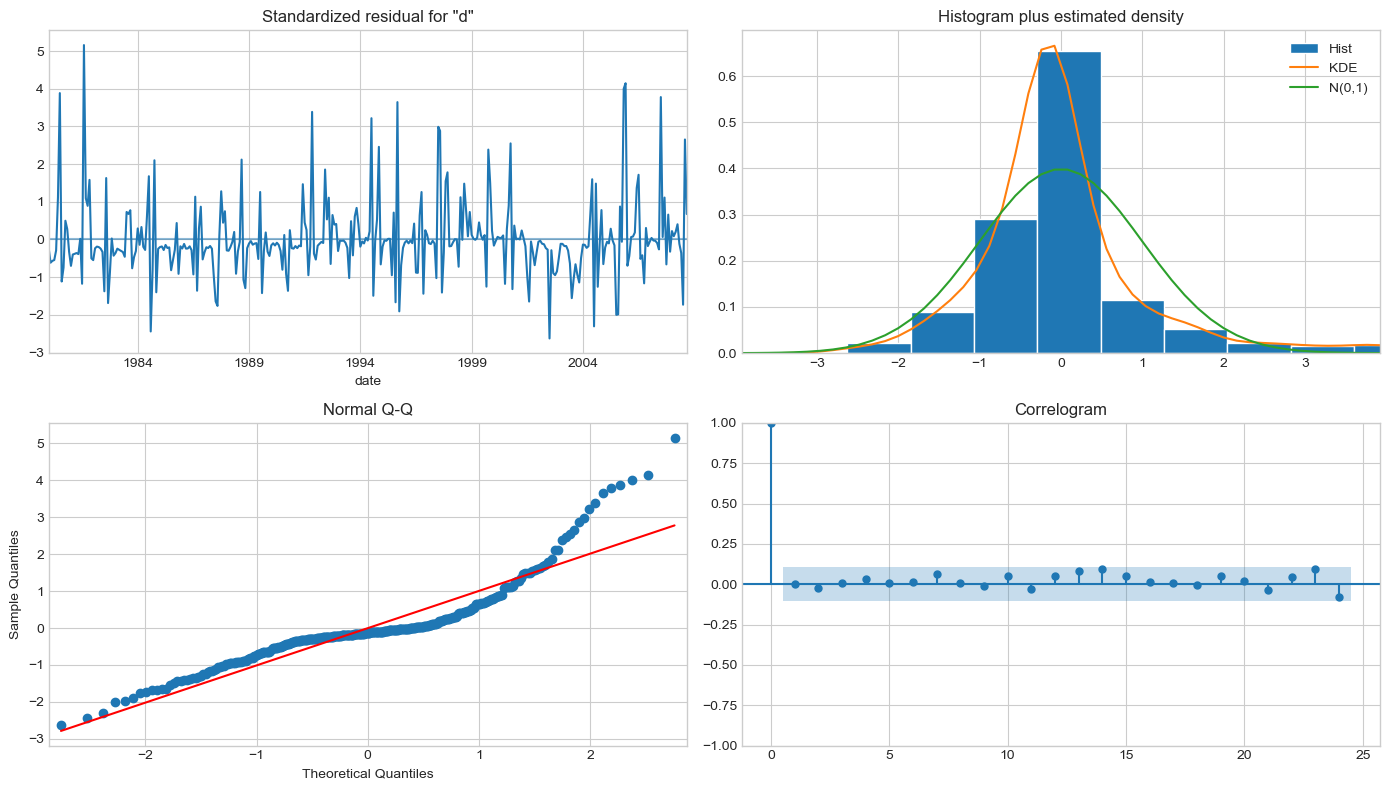

In [7]:
res_tr = ARIMA(train_s, order=best_order, seasonal_order=best_so).fit()
resid = res_tr.resid.iloc[13:]            # drop the first 13 points (model start-up transient)

p_, _, q_ = best_order; P_, D_, Q_, _ = best_so
lb = acorr_ljungbox(resid, lags=[12, 24], model_df=p_ + q_ + P_ + Q_, return_df=True)
print("Ljung-Box (want p > 0.05):"); print(lb.round(4).to_string())
jb = res_tr.test_normality(method="jarquebera")[0]
bv = res_tr.test_heteroskedasticity(method="breakvar")[0]
print(f"\nJarque-Bera p = {jb[1]:.4f} | skew = {jb[2]:.2f} | kurtosis = {jb[3]:.2f}")
print(f"Heteroskedasticity (breakvar) p = {bv[1]:.4f}")
try:
    print("AR roots modulus:", np.round(np.abs(res_tr.arroots), 3), "| MA roots modulus:", np.round(np.abs(res_tr.maroots), 3), "(all should be > 1)")
except Exception as e:
    print("root check unavailable:", e)

fig = res_tr.plot_diagnostics(figsize=(14, 8), lags=24); plt.tight_layout(); save_fig("03_residual_diagnostics"); plt.show()

## 7 · Final test-set evaluation
Refit on **train + validation**, then forecast the 44 test months one step ahead. The same three naïve baselines as in the ML notebook are scored alongside.

In [8]:
tv = pd.concat([train_s, val_s])
# Same sample as the ML notebook (its first target month is Jan 1981 because of the 11-month lag),
# so the climatology baseline is identical in both notebooks.
tv_clim = tv[tv.index >= "1981-01-01"]
clim_tv = tv_clim.groupby(tv_clim.index.month).mean()

def fit_and_forecast(order, so):
    r = ARIMA(tv, order=order, seasonal_order=so).fit()
    return r, one_step(r, test_s)

res_best, pred_best = fit_and_forecast(best_order, best_so)
res_arma, pred_arma = fit_and_forecast((1, 0, 1), (0, 0, 0, 0))

multi = res_best.forecast(steps=len(test_s))            # one origin, 44 steps ahead, no updating

preds = {
    "ARMA(1,1)":                       pred_arma.values,
    label(best_order, best_so):        pred_best.values,
    "Persistence":                     ts.shift(1)[test_s.index].values,
    "Seasonal naive":                  ts.shift(12)[test_s.index].values,
    "Climatology":                     test_s.index.month.map(clim_tv).values,
}
test_table = pd.DataFrame({k: kd.evaluate(test_s, v) for k, v in preds.items()}).T
test_table.loc[f"{label(best_order, best_so)} (44-step, no updating)"] = kd.evaluate(test_s, multi.values)
test_table.sort_values("RMSE").round(3)

,MAE,MSE,RMSE,NSE
"SARIMA(1, 0, 1)x(1, 0, 1)[12]",42.210,3694.764,60.785,0.772
"SARIMA(1, 0, 1)x(1, 0, 1)[12] (44-step, no updating)",51.575,4676.993,68.389,0.712
Climatology,50.508,4776.166,69.110,0.706
Seasonal naive,58.790,6300.189,79.374,0.612
"ARMA(1,1)",66.601,6908.448,83.117,0.575
Persistence,66.331,8458.452,91.970,0.479


In [9]:
# Sanity check: baselines must match notebook 04 exactly (same months, same definitions)
import os
ml_path = f"{TAB_DIR}/ml_test_metrics.csv"
if os.path.exists(ml_path):
    ml = pd.read_csv(ml_path, index_col="model")
    for b in ["Persistence", "Seasonal naive", "Climatology"]:
        assert abs(ml.loc[b, "RMSE"] - test_table.loc[b, "RMSE"]) < 0.01, f"{b} differs between notebooks!"
    print("OK: baseline scores agree with notebook 04.")
else:
    print("Run notebook 04 to enable the cross-notebook consistency check.")

OK: baseline scores agree with notebook 04.


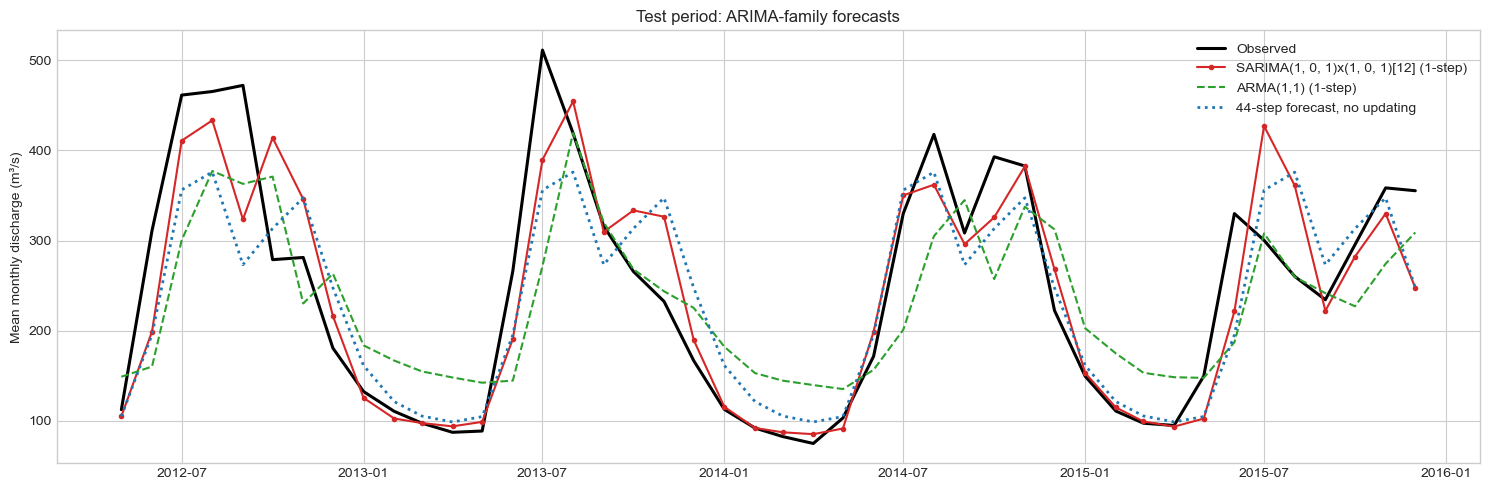

In [10]:
fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(test_s.index, test_s, color="black", lw=2.2, label="Observed")
ax.plot(test_s.index, pred_best, color="#d62728", marker="o", ms=3, label=f"{label(best_order, best_so)} (1-step)")
ax.plot(test_s.index, pred_arma, color="#2ca02c", ls="--", label="ARMA(1,1) (1-step)")
ax.plot(test_s.index, multi, color="#1f77b4", ls=":", lw=2, label="44-step forecast, no updating")
ax.set(title="Test period: ARIMA-family forecasts", ylabel="Mean monthly discharge (m³/s)"); ax.legend()
plt.tight_layout(); save_fig("03_test_forecast"); plt.show()

In [11]:
# Save for the ML notebook / dashboard (one-step forecasts only: directly comparable to ML)
out = pd.DataFrame({"observed": test_s.values,
                    "ARMA(1,1)": pred_arma.values,
                    label(best_order, best_so): pred_best.values}, index=test_s.index)
out.index.name = "month"
out.round(3).to_csv(f"{TAB_DIR}/arima_test_predictions.csv")
test_table.sort_values("RMSE").round(4).to_csv(f"{TAB_DIR}/arima_test_metrics.csv", index_label="model")
val_table.round(4).to_csv(f"{TAB_DIR}/arima_validation_metrics.csv", index_label="model")
print("saved ->", TAB_DIR)

saved -> ../reports/tables


➡️ Now re-run the last cell of **`04_ml_forecasting.ipynb`** to produce the final model comparison table (ARIMA family vs. ML vs. baselines) in `reports/tables/final_model_comparison.csv`.

### Key findings
* **Stationarity:** The raw monthly series gives conflicting tests (ADF p = 0.081 fails to reject a unit root; KPSS p ≥ 0.10 does not reject stationarity). After removing the seasonal cycle (anomalies) or taking a seasonal difference, both tests agree the series is stationary; so is the annual mean series (ADF p = 0.006).
* **Model search:** 72 ARIMA/SARIMA candidates were fitted on the training months; 3 failed to converge and were excluded. Seasonal terms were clearly needed. AIC is only comparable within the same differencing order, so finalists were compared on the validation months instead.
* **Selection:** On validation (one-step-ahead) SARIMA(1,0,1)×(1,0,1)[12] had the lowest RMSE (99.2 m³/s) but was virtually tied with SARIMA(2,0,1)×(0,1,1)[12] (99.5); the non-seasonal ARMA(1,1) from the original project was much worse (122.9).
* **Diagnostics:** Residuals have no remaining autocorrelation (Ljung-Box p = 0.64 at lag 12 and 0.65 at lag 24). They are not normal (Jarque-Bera p < 0.001, skew 1.57, kurtosis 8.0) because of occasional flood months, so Gaussian prediction intervals would be unreliable. The variance-stability test did not detect a change (p = 0.33). The seasonal AR/MA roots lie extremely close to the unit circle (rounded modulus 1.000-1.001), a sign that the seasonal part is near the boundary of stationarity/invertibility and that seasonal differencing is an equally good alternative - consistent with the near-tie in finding 3.
* **Test performance:** (44 months, one-step-ahead). SARIMA: MAE 42.2, RMSE 60.8, NSE 0.77 vs climatology MAE 50.5, RMSE 69.1 → reductions of 16 % (MAE), 23 % (MSE), 12 % (RMSE). The non-seasonal ARMA(1,1) (RMSE 83.1) was worse than climatology; the seasonal terms improved it by 27 % (RMSE).
* **Horizon matters:** The same SARIMA evaluated as one 44-step forecast with no updating scored RMSE 68.4 about the same as climatology, because long-horizon forecasts of a seasonal model converge to the seasonal average.